# Simulations

SIGMA.1025 • 3,888 spots • 5 occupied native clusters.

This notebook reproduces the selected panel result with **integration = 230, contrastive = 0.8, mix = 0.3**.
The default run uses the included saved representation and spatial labels; it does not retrain the model.
To run preprocessing and training on your own copy of the input data, set `RUN_TRAINING = True` and provide the files listed in the installation guide.
The visualization cells deliberately retain the selected panel result so that a new training run cannot silently replace the reference figure.

## Setup

In [1]:
from pathlib import Path
import hashlib
import json
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
import sigma
from sigma import run

RUN_TRAINING = False
asset_dir = Path('../assets/simulation')
output_dir = Path('../../results/simulation_training')
config = {
    'preset': 'simulation',
    'data_root': '../../data/simulation',
    'output': str(output_dir),
    'integ': 230,
    'contrastive': 0.8,
    'device': 'cpu',
}
print('SIGMA', sigma.__version__)
print('Mode:', 'training + reference visualization' if RUN_TRAINING else 'saved-panel visualization')

SIGMA 0.3.0
Mode: saved-panel visualization


## Preprocessing

In [2]:
if RUN_TRAINING:
    run(config, prepare_only=True, resume=True,
        log_file=output_dir / 'preprocessing.log')
    print('Prepared inputs:', output_dir.as_posix())
else:
    print('Using included saved-panel inputs:', asset_dir.as_posix())

Using included saved-panel inputs: ../assets/simulation


## Training

In [3]:
if RUN_TRAINING:
    run(config, resume=True, log_file=output_dir / 'training.log')
    print('New training outputs:', output_dir.as_posix())
else:
    print('Training skipped. Figures below reproduce the selected saved trial.')

Training skipped. Figures below reproduce the selected saved trial.


## Load the selected result

In [4]:
metadata = json.loads((asset_dir / 'metadata.json').read_text())
result_file = asset_dir / 'results.npz'
assert hashlib.sha256(result_file.read_bytes()).hexdigest() == metadata['results_sha256']
with np.load(result_file, allow_pickle=False) as saved:
    result = {key: saved[key] for key in saved.files}

assert len(set(result['obs_ids'])) == metadata['n_spots']
assert np.isfinite(result['embedding']).all()
assert np.isfinite(result['spatial']).all()
assert len(set(result['native_clusters'])) == metadata['n_native_clusters']
for native, display in metadata['color_mapping'].items():
    assert np.all(result['display_labels'][result['native_clusters'] == native] == display)
expected_colors = np.asarray([metadata['palette'][x] for x in result['display_labels']])
np.testing.assert_array_equal(result['colors'], expected_colors)
print(metadata['trial'])
print(f"Verified {metadata['n_spots']:,} spots and {metadata['n_native_clusters']} native clusters.")

integ_230__contrastive_0p8__mix_0p3
Verified 3,888 spots and 5 native clusters.


## Batch-colored UMAP

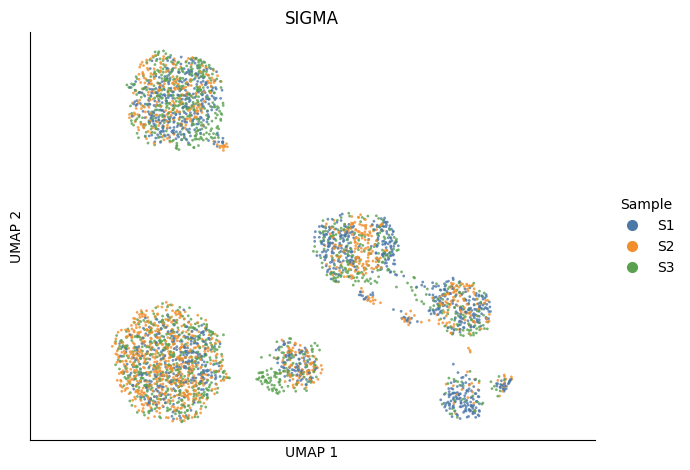

In [5]:
if 'umap' in result:
    umap_xy = result['umap']  # Exact coordinates used in the Simulation panel.
else:
    import warnings
    from tqdm import TqdmWarning
    with warnings.catch_warnings():
        warnings.filterwarnings('ignore', message='IProgress not found.*', category=TqdmWarning)
        from umap import UMAP
    umap_xy = UMAP(n_neighbors=15, min_dist=0.5, metric='euclidean',
                   random_state=1234, n_jobs=1).fit_transform(result['embedding'])
assert np.isfinite(umap_xy).all()

plt.rcParams.update({'font.family': 'DejaVu Sans', 'pdf.fonttype': 42,
                     'svg.fonttype': 'none', 'figure.facecolor': 'white'})
samples = metadata['sample_order']
sample_colors = ['#4C78A8', '#F28E2B', '#59A14F', '#E15759', '#B279A2', '#76B7B2', '#EDC948']
batch_palette = dict(zip(samples, sample_colors))
order = np.random.default_rng(0).permutation(len(umap_xy))
fig, ax = plt.subplots(figsize=(7.0, 4.8))
ax.scatter(*umap_xy[order].T, s=4, alpha=0.8, linewidths=0,
           c=[batch_palette[x] for x in result['samples'][order]], rasterized=True)
ax.set_aspect('equal', adjustable='datalim')
ax.set(xlabel='UMAP 1', ylabel='UMAP 2', title='SIGMA')
ax.set_xticks([]); ax.set_yticks([])
ax.spines[['top', 'right']].set_visible(False)
handles = [Line2D([], [], linestyle='', marker='o', color=batch_palette[s],
                  label=t, markersize=7) for s,t in zip(samples,metadata['sample_titles'])]
ax.legend(handles=handles, title='Sample', frameon=False, loc='center left', bbox_to_anchor=(1.02,0.5))
fig.tight_layout()
figure_dir = Path('../../results') / (metadata['preset'] + '_panel') / 'figures'
figure_dir.mkdir(parents=True, exist_ok=True)
fig.savefig(figure_dir / 'batch_umap.pdf', bbox_inches='tight')
fig.savefig(figure_dir / 'batch_umap.png', dpi=180, bbox_inches='tight')
plt.show()

## Spatial domains

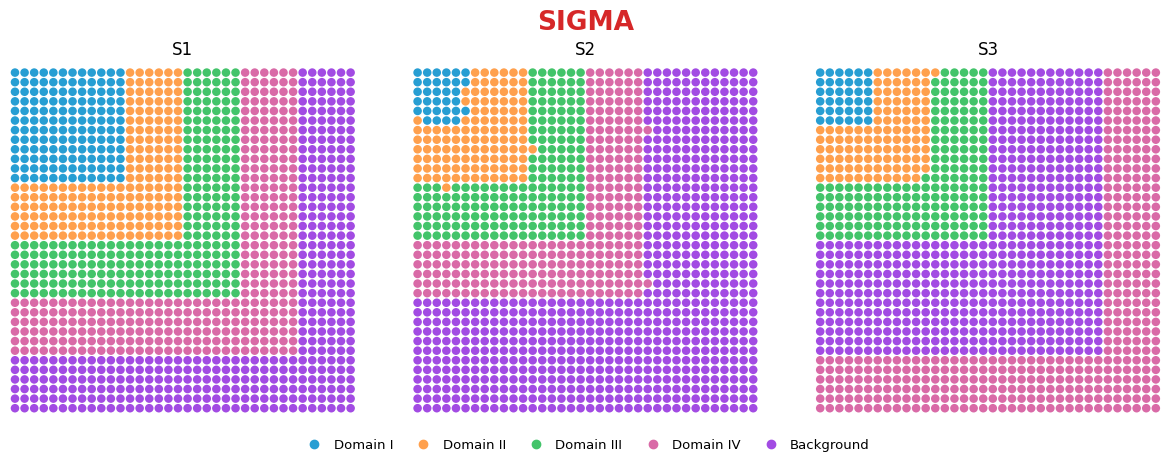

In [6]:
# Use the exact panel coordinates and per-spot colors; retain the native partition.
n = len(samples)
if n == 7:
    width, height, legend_columns, bottom = 21.0, 4.7, 5, 0.28
elif n == 3:
    width, height, legend_columns, bottom = 12.4, 5.8, 3, 0.31
    if metadata['preset'] == 'simulation':
        height, legend_columns, bottom = 4.8, 5, 0.14
else:
    width, height, legend_columns, bottom = 6.8, 6.4, 7, 0.18
fig, axes = plt.subplots(1, n, figsize=(width,height), squeeze=False)
fig.subplots_adjust(left=0.025, right=0.975, top=0.86, bottom=bottom, wspace=0.08)
fig.suptitle('SIGMA', fontsize=19, fontweight='bold', color='#D62728', y=0.98)
for ax, sample, title in zip(axes[0], samples, metadata['sample_titles']):
    mask = result['samples'] == sample
    xy = result['spatial'][mask]
    # Scale points with map width while preserving the panel's circular/square texture.
    size = 18 if n == 7 else (11 if n == 3 else 14)
    if metadata['preset'] == 'simulation':
        size = 38
    ax.scatter(*xy.T, c=result['colors'][mask], s=size, marker=metadata['marker'],
               linewidths=0, edgecolors='none', rasterized=True)
    if metadata['preset'] == 'simulation':
        dx,dy = [np.min(np.diff(np.unique(xy[:,i]))) for i in (0,1)]
        ax.set_xlim(xy[:,0].min()-.52*dx, xy[:,0].max()+.52*dx)
        ax.set_ylim(xy[:,1].min()-.52*dy, xy[:,1].max()+.52*dy)
    else:
        ax.margins(0.03)
    if metadata['invert_y']:
        ax.invert_yaxis()
    ax.set_aspect('equal', adjustable='box')
    display_title = f'Section {samples.index(sample)+1}' if n == 7 else title
    ax.set_title(display_title, fontsize=12, pad=9)
    ax.axis('off')

legend = metadata['legend']
handles = [Line2D([], [], linestyle='', marker='o', color=x['color'],
                  markersize=6, label=x['label']) for x in legend]
# Matplotlib fills legend columns first; reorder handles to read left-to-right.
indices = [i for col in range(legend_columns) for i in range(col,len(handles),legend_columns)]
fig.legend(handles=[handles[i] for i in indices], ncol=legend_columns,
           loc='lower center', bbox_to_anchor=(0.5,0.035), frameon=False,
           fontsize=9.5, columnspacing=1.3, handletextpad=0.45, labelspacing=1.0)
fig.savefig(figure_dir / 'spatial_domains.pdf', bbox_inches='tight')
fig.savefig(figure_dir / 'spatial_domains.png', dpi=180, bbox_inches='tight')
plt.show()

## Provenance

The accompanying `metadata.json` records the exact panel path, trial path, input checksums, color correspondence and native cluster count. The unchanged `trial_metrics.json` records the original run; its runtime and metrics are archival measurements, not measurements from this notebook execution.

These inputs support plot reproduction without access to the raw count matrices. Full model reruns require the original input files and preprocessing provenance. See the Reproducibility page for tested environments, model smoke tests and remaining submission requirements.